In [1]:
import kagglehub
import pandas as pd
# Download latest version
path = kagglehub.dataset_download("uom190346a/sleep-health-and-lifestyle-dataset")
path = path + "/Sleep_health_and_lifestyle_dataset.csv"
print("Path to dataset files:", path)

Path to dataset files: /home/girlando/.cache/kagglehub/datasets/uom190346a/sleep-health-and-lifestyle-dataset/versions/2/Sleep_health_and_lifestyle_dataset.csv


In [2]:
df = pd.read_csv(path, index_col="Person ID")
df["Sleep Disorder"] = df["Sleep Disorder"].fillna("None")
df["Systolic Blood Pressure"] = df["Blood Pressure"].apply(lambda x: int(x.split("/")[0]))
df["Diastolic Blood Pressure"] = df["Blood Pressure"].apply(lambda x: int(x.split("/")[1]))

In [3]:
df.info();

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 1 to 374
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Gender                    374 non-null    str    
 1   Age                       374 non-null    int64  
 2   Occupation                374 non-null    str    
 3   Sleep Duration            374 non-null    float64
 4   Quality of Sleep          374 non-null    int64  
 5   Physical Activity Level   374 non-null    int64  
 6   Stress Level              374 non-null    int64  
 7   BMI Category              374 non-null    str    
 8   Blood Pressure            374 non-null    str    
 9   Heart Rate                374 non-null    int64  
 10  Daily Steps               374 non-null    int64  
 11  Sleep Disorder            374 non-null    str    
 12  Systolic Blood Pressure   374 non-null    int64  
 13  Diastolic Blood Pressure  374 non-null    int64  
dtypes: float64(1), int64(

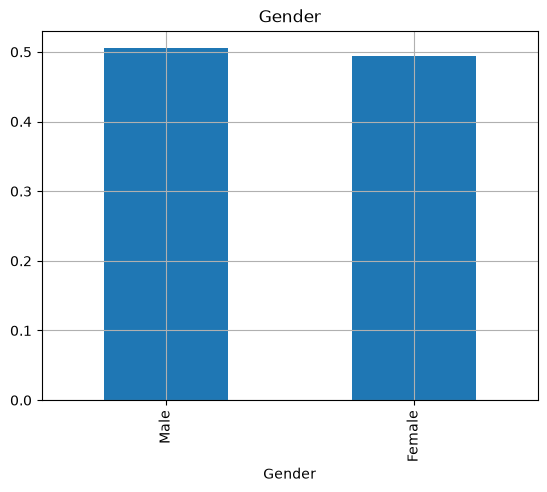

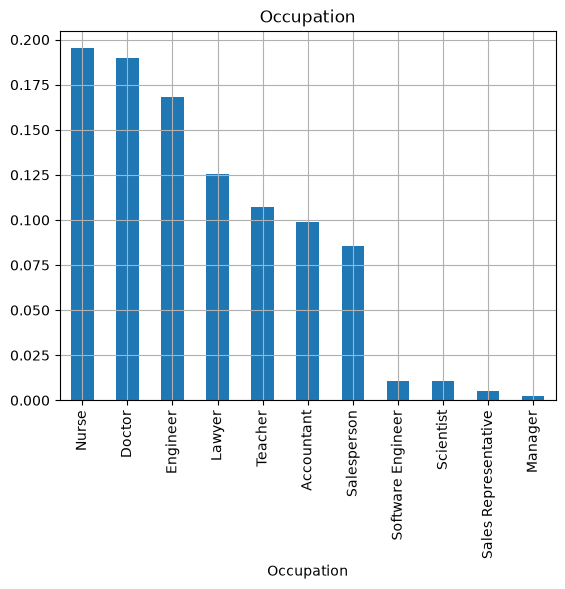

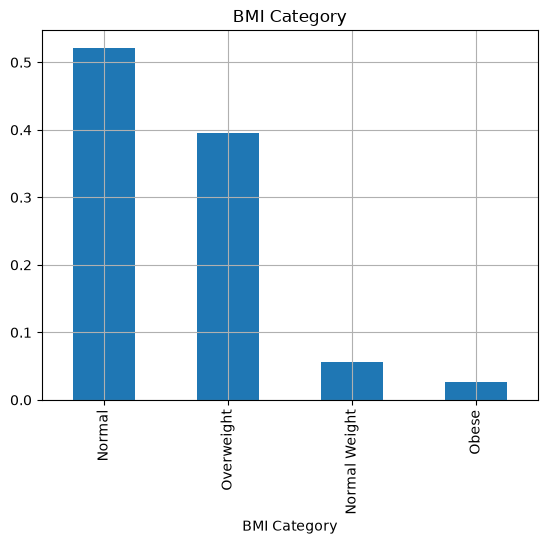

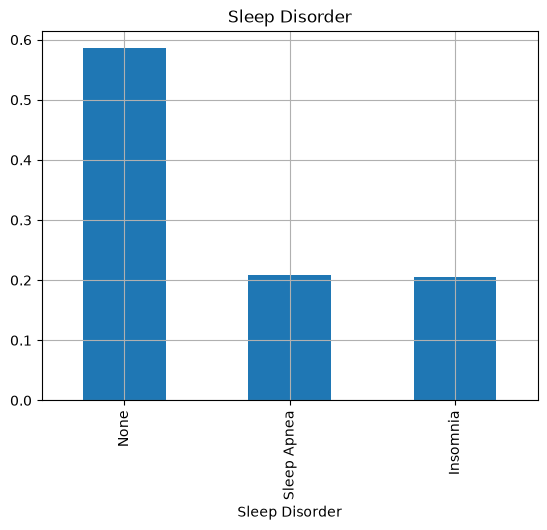

In [8]:
from matplotlib import pyplot as plt
for colname in ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]:
    df[colname].value_counts(normalize=True).plot(kind="bar", title=colname);
    plt.grid();
    plt.show();

In [ ]:
for colname in ["Occupation", "BMI Category", "Sleep Disorder"]:
    pd.crosstab(df["Gender"], df[colname], normalize=True).plot.bar(stacked = True, cmap="tab20", title = f"Gender - {colname}").legend(bbox_to_anchor=(1.04, 0), loc="lower left", borderaxespad=0)

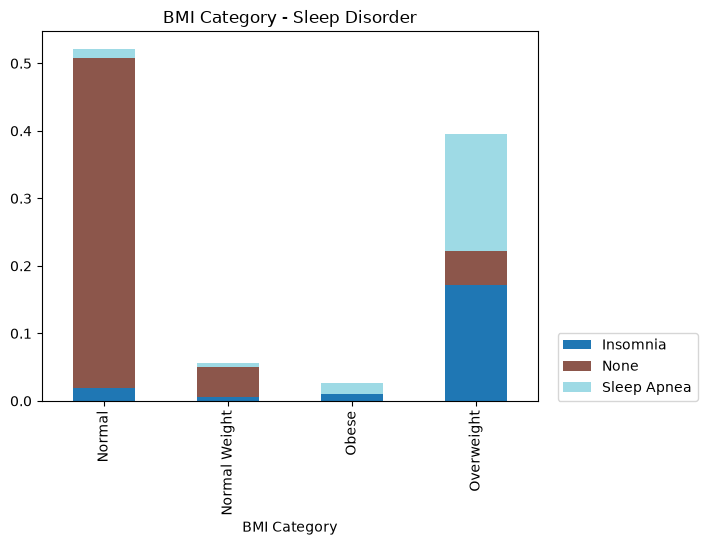

In [21]:
pd.crosstab(df["BMI Category"], df["Sleep Disorder"], normalize=True).plot.bar(stacked = True, cmap="tab20", title = f"BMI Category - Sleep Disorder").legend(bbox_to_anchor=(1.04, 0), loc="lower left", borderaxespad=0)
